In [7]:
import pandas as pd

In [8]:
df1 = pd.read_csv('dem-public-transport-journeys.csv')

In [9]:
print(df1.head())

          Total Trips  Bus Eireann  Dublin City Bus  Irish Rail  Luas
0  Q2 20        14.41         0.46            10.11        1.61  2.23
1  Q3 20        27.85         0.81            19.27        2.75  5.03
2  Q4 20        16.32         0.48            13.38        0.89  1.57
3  Q1 21        20.53         0.68            14.98        2.00  2.87
4  Q2 21        27.23         0.90            18.43        3.10  4.80


In [10]:
df2 = pd.read_csv('f8db4899-e378-4aa9-9cc8-306b87e692e0.csv')

In [11]:
print(df2.head())

   _id Quarter  Public Transport million trips  \
0    1   Q3 07                             NaN   
1    2   Q4 07                             NaN   
2    3   Q1 08                             NaN   
3    4   Q2 08                             NaN   
4    5   Q3 08                             NaN   

   Public Transport million trips2  Bus Éireann  Dublin City Bus  Irish Rail  \
0                              NaN          NaN              NaN         NaN   
1                              NaN          NaN              NaN         NaN   
2                              NaN          NaN              NaN         NaN   
3                              NaN          NaN              NaN         NaN   
4                              NaN          NaN              NaN         NaN   

   Luas  YoY Public Transport  QoQ Public Transport  ... unsafe__21  \
0   NaN                   NaN                   NaN  ...        NaN   
1   NaN                   NaN                   NaN  ...        NaN   
2   N

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [5]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
X = df[numeric_cols].dropna()

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [13]:
from sklearn.cluster import KMeans

In [14]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [9]:
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index: {db_score:.4f}")

Silhouette Score: 0.5822
Davies-Bouldin Index: 0.5190


In [12]:
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

In [14]:
target_col = numeric_cols[0] 
print(target_col)

Total Trips


In [15]:
model = ARIMA(df[target_col].dropna(), order=(1, 1, 1))
model_fit = model.fit()

In [16]:
forecast = model_fit.forecast(steps=4)
print(forecast)

25    78.431689
26    80.247401
27    82.047277
28    83.831455
Name: predicted_mean, dtype: float64


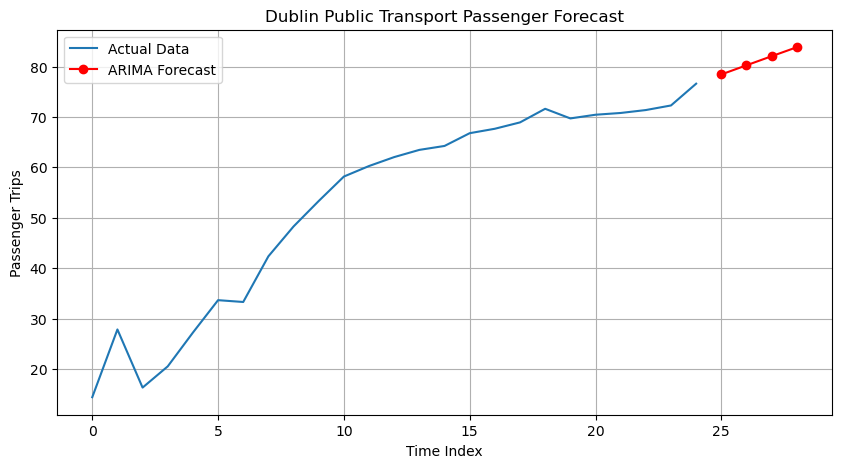

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df[target_col].dropna(), label='Actual Data')
plt.plot(forecast.index, forecast, label='ARIMA Forecast', color='red', marker='o')
plt.legend()
plt.title('Dublin Public Transport Passenger Forecast')
plt.xlabel('Time Index')
plt.ylabel('Passenger Trips')
plt.grid(True)
plt.show()